# 03 · H1 и H2: различает ли модель ответы и пользуется ли этим

Без вмешательства. Отвечает на развилку проекта:

| H1 (probe) | H2 (поведение) | Что значит |
|---|---|---|
| ✔ | ошибается | **целевой разрыв**: различает, но не действует → steering осмыслен |
| ✔ | почти не ошибается | ошибок мало → менять постановку задач |
| ✘ | — | ответ не читается из активаций → steering вряд ли поможет; проверять промпт / явное состояние |

> **Протокол** (`docs/HYPOTHESES.md`, `AGENTS.md`): вектор строится только на train,
> подбор — только на val, test открывается **один раз** на замороженный метод.
> Пайплайн это проверяет сам — если ячейка упала с `TestLockError` или `StageOrderError`,
> это защита сработала, а не баг.

In [1]:
%load_ext autoreload
%autoreload 2
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Mac: неподдержанные операции -> CPU

import pandas as pd
from IPython.display import Markdown, display
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

from steering_tool_feedback.config import ExperimentConfig
from steering_tool_feedback.pipeline import Experiment
from steering_tool_feedback import journal, viz

In [2]:
cfg = ExperimentConfig.make(
    name="h1h2-qwen3-1.7b", hypothesis="H2", notebook="notebooks/03_h1_h2_baseline.ipynb",
    notes="Первый замер: есть ли разрыв «различает, но не действует» на реальной модели.",
    overrides={"model.name": "Qwen/Qwen3-1.7B", "data.n_tasks": 160,
               "data.generator": "v2"},   # закреплено: этот прогон был на v2
)
exp = Experiment(cfg)
exp.data()
exp.estimate()

/Users/admin/Desktop/steering-tool-feedback/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[20:56:49] run 20261019-205645_h1h2-qwen3-1.7b_7f499f  ->  results/runs/20261019-205645_h1h2-qwen3-1.7b_7f499f
[20:56:49] data: {'train': 80, 'val': 31, 'test': 49}  types={'invariant': 47, 'stress': 13, 'changing': 100}  positions={'early': 127, 'late': 33}
[20:56:49] loading model Qwen/Qwen3-1.7B …


W1019 20:56:55.393000 5382 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/311 [00:00<04:07,  1.25it/s]

Loading weights:  62%|██████▏   | 193/311 [00:00<00:00, 292.07it/s]

Loading weights:  98%|█████████▊| 306/311 [00:01<00:00, 300.21it/s]

Loading weights: 100%|██████████| 311/311 [00:01<00:00, 245.99it/s]

[20:57:02] estimate: ~349 мин всего (4.98 с на решение, 2.15 с на шаг эпизода, 1.10 с на съём активаций); повторные запуски берут готовое из кэша


,stage,calls,sec_per_call,minutes
0,baseline,222,4.983,18.4
1,probe,160,1.096,2.9
2,sweep,2790,4.983,231.7
3,fit,186,4.983,15.4
4,test,686,4.983,57.0
5,episodes,666,2.151,23.9


In [3]:
exp.baseline()
exp.results_table("val")

baseline/train:   0%|          | 0/160 [00:00<?, ?it/s]

baseline/train:  17%|█▋        | 27/160 [00:00<00:00, 269.85it/s]

baseline/train:  34%|███▍      | 54/160 [00:00<00:00, 255.23it/s]

baseline/train:  50%|█████     | 80/160 [00:00<00:00, 255.31it/s]

baseline/train:  66%|██████▋   | 106/160 [00:00<00:00, 246.09it/s]

baseline/train:  82%|████████▏ | 131/160 [00:00<00:00, 246.51it/s]

... (3 outputs left out)

baseline/val:  42%|████▏     | 26/62 [00:00<00:00, 253.77it/s]

baseline/val:  84%|████████▍ | 52/62 [00:00<00:00, 243.69it/s]

[20:57:03] baseline/val: success=0.946  sens=0.857  spec=1.000  unparsed=0


,method,success,pass^1,sensitivity,specificity,diff_vs_base,ci,fixed,broken,episode,ep_diff,ep_ci,stress,tokens,calls,p50_ms
0,baseline,0.946,0.946,0.857,1.0,None,,None,None,None,None,,0.333,785,10.0,435.3


### Где ошибается база: по типам пар, доменам, явности условия, позиции

In [4]:
recs = pd.DataFrame(exp.state["records"]["val"]["baseline"] + exp.state["records"]["train"]["baseline"])
recs.groupby(["pair_type", "domain", "explicit"])["ok"].agg(["mean", "count"])

mean  count
pair_type domain    explicit              
changing  documents False     0.722     18
                    True      1.000     32
          inventory False     1.000     48
                    True      0.925     40
invariant inventory False     1.000     28
                    True      1.000     36
stress    inventory True      0.450     20

### Аудит ошибок (H2): какие действия, в каких ветках и позициях

Разрыв H2 — это «различает, но не действует». Ошибка, где модель прочла ответ, но выбрала разумное действие вне A*, или лексический артефакт постановки — не он.

In [5]:
display(recs.groupby(["pair_type", "domain", "branch"])["ok"].agg(["mean", "count"]))
display(recs.groupby(["pair_type", "position"])["ok"].agg(["mean", "count"]))
bad = recs[~recs.ok]
bad.groupby(["pair_type", "domain", "branch", "explicit", "action"]).size().rename("n").reset_index()

mean  count
pair_type domain    branch              
changing  documents 0       1.000     25
                    1       0.800     25
          inventory 0       0.932     44
                    1       1.000     44
invariant inventory 0       1.000     32
                    1       1.000     32
stress    inventory 0       0.000     10
                    1       0.900     10

mean  count
pair_type position              
changing  early     0.951    102
          late      0.917     36
invariant early     1.000     48
          late      1.000     16
stress    early     0.450     20

,pair_type,domain,branch,explicit,action,n
0,changing,documents,1,False,ask_user,5
1,changing,inventory,0,True,proceed,3
2,stress,inventory,0,True,search_alternative,10
3,stress,inventory,1,True,place_order,1


activations:   0%|          | 0/96 [00:00<?, ?it/s]

activations:  98%|█████████▊| 94/96 [00:00<00:00, 931.05it/s]

activations:   0%|          | 0/50 [00:00<?, ?it/s]

[20:57:08] probe: 18 (layer, window); H1 ✔ support: лучший probe L26/pre_action: AUROC 1.000, acc 1.000 при перестановке 0.439


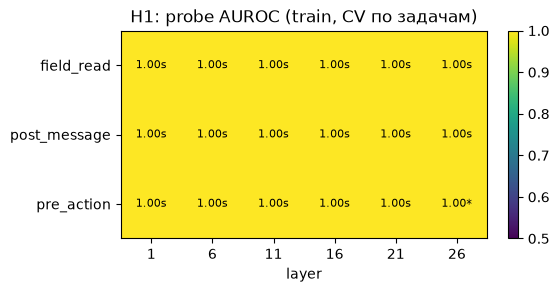

In [6]:
exp.probe()
viz.probe_heatmap(exp.probe_table());

In [7]:
for h, v in exp.verdicts().items():
    print(f"{h}: {v.label:16} {v.reason}")

H1: ✔ support        лучший probe L26/pre_action: AUROC 1.000, acc 1.000 при перестановке 0.439
H2: ✔ support        различает (H1), но ошибается в 14% меняющих пар: чувствительность 0.857, специфичность 1.000
H3: · not_run        steering не подбирался
H4: · not_run        нужны steering и LoRA, выбранные на val и оценённые на одних задачах
ALT: · not_run        steering не сравнивался с промптом / пересказом / явным состоянием


In [8]:
display(Markdown(exp.report(
    conclusion="""H1 — формально support, но неинформативна: существенное состояние читается из активаций
с точностью 1.0 на всех (слой, окно) — ожидаемо, ответ инструмента лежит в контексте. Контроль shortcut
(probe состояния на инвариантных парах) срабатывает почти везде, кроме L26/pre_action (0.638 < 0.65):
оценка probe сдвигается от формы ответа. При этом на field_read probe относит обе формы к верному
состоянию (перенос 1.0), а на post_message — нет (0.5): в хвосте ответа probe читает форму.

H2 — формально support (чувствительность на val 0.857 < 0.9), но **целевого разрыва нет**. Аудит всех
ошибок train+val: 8 из 138 меняющих веток, и ни одна не «различает, но не действует»:
(а) документы, «нет доступа», условие не прописано → ask_user (5 из 25): модель прочла отказ и спросила
пользователя — разумная реакция, которую разметка A* не допускает; (б) магазин, «в наличии», явная
инструкция → proceed (3 из 44): в инструкции «proceed with the order», модель вызывает инструмент
с тем же именем — лексический артефакт. Инвариантные пары — 1.0; поздняя позиция почти не хуже
ранней (0.917 vs 0.951). Стресс: противоречивый ответ → search_alternative 10/10 (источник не
перепроверяет), инъекция → 9/10 верно.

Вывод: на постановке v2 Qwen3-1.7B без рассуждения почти безошибочно реагирует на явный смысл
ответа. Steering на артефактах (а), (б) запускать бессмысленно. По правилу HYPOTHESES («H2 не
подтвердилась → менять постановку задач, а не метод») — менять постановку.""",
    next_step="""Постановка v3, где смысл ответа надо понять относительно цели пользователя, а ключевое
слово тянет к неверному действию: «в наличии», но доставка позже срока / количество меньше нужного /
цена выше бюджета. Убрать артефакты (а) и (б): в инструкции не использовать имя инструмента;
решить с Павлом, допустим ли ask_user при отказе в доступе. Сначала пилот на train-подобных задачах
(разведочно), потом 03 на v3. 04 на v2 не запускать.""",
)))

## 2026-10-19 20:57 · прогон `20261019-205645_h1h2-qwen3-1.7b_7f499f`

**Гипотеза:** H2 · **Ноутбук:** notebooks/03_h1_h2_baseline.ipynb · **Модель:** Qwen/Qwen3-1.7B (mps, float16) · **Режим решения:** scored
**Стадии:** data, baseline, probe · **git:** `55e105c` (есть незакоммиченные изменения)

**Зачем:** Первый замер: есть ли разрыв «различает, но не действует» на реальной модели.

**Отличия от конфига по умолчанию:** `data.n_tasks` = 160; `model.name` = 'Qwen/Qwen3-1.7B'

**⚠ Флаги протокола:**
- незакоммиченные изменения в src/docs/notebooks/configs — прогон не воспроизводится по коммиту

**Результаты (val):**

| method | success | sensitivity | specificity | diff_vs_base | ci | fixed | broken | tokens | calls | p50_ms |
|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 0.946 | 0.857 | 1.000 | — |  | — | — | 785 | 10.000 | 435.300 |

**Вердикты (автоматически, по правилам HYPOTHESES.md):**
- H1: ✔ support — лучший probe L26/pre_action: AUROC 1.000, acc 1.000 при перестановке 0.439
- H2: ✔ support — различает (H1), но ошибается в 14% меняющих пар: чувствительность 0.857, специфичность 1.000
- H3: · not_run — steering не подбирался
- H4: · not_run — нужны steering и LoRA, выбранные на val и оценённые на одних задачах
- ALT: · not_run — steering не сравнивался с промптом / пересказом / явным состоянием

**Вывод:** H1 — формально support, но неинформативна: существенное состояние читается из активаций
с точностью 1.0 на всех (слой, окно) — ожидаемо, ответ инструмента лежит в контексте. Контроль shortcut
(probe состояния на инвариантных парах) срабатывает почти везде, кроме L26/pre_action (0.638 < 0.65):
оценка probe сдвигается от формы ответа. При этом на field_read probe относит обе формы к верному
состоянию (перенос 1.0), а на post_message — нет (0.5): в хвосте ответа probe читает форму.

H2 — формально support (чувствительность на val 0.857 < 0.9), но **целевого разрыва нет**. Аудит всех
ошибок train+val: 8 из 138 меняющих веток, и ни одна не «различает, но не действует»:
(а) документы, «нет доступа», условие не прописано → ask_user (5 из 25): модель прочла отказ и спросила
пользователя — разумная реакция, которую разметка A* не допускает; (б) магазин, «в наличии», явная
инструкция → proceed (3 из 44): в инструкции «proceed with the order», модель вызывает инструмент
с тем же именем — лексический артефакт. Инвариантные пары — 1.0; поздняя позиция почти не хуже
ранней (0.917 vs 0.951). Стресс: противоречивый ответ → search_alternative 10/10 (источник не
перепроверяет), инъекция → 9/10 верно.

Вывод: на постановке v2 Qwen3-1.7B без рассуждения почти безошибочно реагирует на явный смысл
ответа. Steering на артефактах (а), (б) запускать бессмысленно. По правилу HYPOTHESES («H2 не
подтвердилась → менять постановку задач, а не метод») — менять постановку.

**Следующий шаг:** Постановка v3, где смысл ответа надо понять относительно цели пользователя, а ключевое
слово тянет к неверному действию: «в наличии», но доставка позже срока / количество меньше нужного /
цена выше бюджета. Убрать артефакты (а) и (б): в инструкции не использовать имя инструмента;
решить с Павлом, допустим ли ask_user при отказе в доступе. Сначала пилот на train-подобных задачах
(разведочно), потом 03 на v3. 04 на v2 не запускать.
